In [1]:
!pip install tensorflow keras

In [2]:
# Baixar o dataset usando um cabeçalho de User-Agent para evitar o erro 403 Forbidden
!wget https://download.mlcc.google.com/mledu-datasets/cats_and_dogs_filtered.zip

--2026-10-21 19:36:58--  https://download.mlcc.google.com/mledu-datasets/cats_and_dogs_filtered.zip
Resolving download.mlcc.google.com (download.mlcc.google.com)... 74.125.132.94, 2607:f8b0:4001:c00::5e
Connecting to download.mlcc.google.com (download.mlcc.google.com)|74.125.132.94|:443... connected.
HTTP request sent, awaiting response... 302 Found
Location: https://dl.google.com/mlcc/mledu-datasets/cats_and_dogs_filtered.zip [following]
--2026-10-21 19:36:58--  https://dl.google.com/mlcc/mledu-datasets/cats_and_dogs_filtered.zip
Resolving dl.google.com (dl.google.com)... 142.251.183.136, 142.251.183.93, 142.251.183.190, ...
Connecting to dl.google.com (dl.google.com)|142.251.183.136|:443... connected.
HTTP request sent, awaiting response... 200 OK
Length: 68606236 (65M) [application/zip]
Saving to: ‘cats_and_dogs_filtered.zip’

cats_and_dogs_filte 100%[===================>]  65.43M   126MB/s    in 0.5s    

2026-10-21 19:36:58 (126 MB/s) - ‘cats_and_dogs_filtered.zip’ saved [68606236

In [3]:
#descompactar o dataset zipado
!unzip cats_and_dogs_filtered.zip


Archive:  cats_and_dogs_filtered.zip
   creating: cats_and_dogs_filtered/
  inflating: cats_and_dogs_filtered/vectorize.py  
   creating: cats_and_dogs_filtered/validation/
   creating: cats_and_dogs_filtered/train/
   creating: cats_and_dogs_filtered/validation/dogs/
  inflating: cats_and_dogs_filtered/validation/dogs/dog.2127.jpg  
  inflating: cats_and_dogs_filtered/validation/dogs/dog.2126.jpg  
  inflating: cats_and_dogs_filtered/validation/dogs/dog.2125.jpg  
  inflating: cats_and_dogs_filtered/validation/dogs/dog.2124.jpg  
  inflating: cats_and_dogs_filtered/validation/dogs/dog.2123.jpg  
  inflating: cats_and_dogs_filtered/validation/dogs/dog.2122.jpg  
  inflating: cats_and_dogs_filtered/validation/dogs/dog.2121.jpg  
  inflating: cats_and_dogs_filtered/validation/dogs/dog.2120.jpg  
  inflating: cats_and_dogs_filtered/validation/dogs/dog.2119.jpg  
  inflating: cats_and_dogs_filtered/validation/dogs/dog.2118.jpg  
  inflating: cats_and_dogs_filtered/validation/dogs/dog.2117.

In [4]:
!rm -rf cats_and_dogs_filtered.zip

In [5]:
import os
import matplotlib.pyplot as plt
import tensorflow as tf


In [6]:
#filtrar o diretório das imagens

# selecionar os dados de treino e validação

dataset_dir = os.path.join(os.getcwd(), 'cats_and_dogs_filtered')

dataset_train_dir = os.path.join(dataset_dir, 'train')
dataset_train_cats_len = len(os.listdir(os.path.join(dataset_train_dir, 'cats')))
dataset_train_dogs_len = len(os.listdir(os.path.join(dataset_train_dir, 'dogs')))

dataset_validation_dir = os.path.join(dataset_dir, 'validation')
dataset_validation_cats_len = len(os.listdir(os.path.join(dataset_validation_dir, 'cats')))
dataset_validation_dogs_len = len(os.listdir(os.path.join(dataset_validation_dir, 'dogs')))

print ('Train Cats: %s' % dataset_train_cats_len)
print ('Train Dogs: %s' % dataset_train_dogs_len)
print ('Validation Cats: %s' % dataset_validation_cats_len)
print ('Validation Dogs: %s' % dataset_validation_dogs_len)

Train Cats: 1000
Train Dogs: 1000
Validation Cats: 500
Validation Dogs: 500


In [7]:
#definir tamanho das imagens para o treino e validação
#scalling: 160 x 160
#valor: cor [posição vectorial]

image_width = 160
image_height = 160
image_color_channel = 3
image_color_channel_size = 255
image_size = (image_width, image_height)
image_shape = image_size + (image_color_channel,)

batch_size = 32
epochs = 20
learning_rate = 0.0001

class_names = ['cat', 'dog']

In [8]:
#objectos datasets

dataset_train = tf.keras.preprocessing.image_dataset_from_directory(
    dataset_train_dir,
    image_size=image_size,
    batch_size=batch_size,
    shuffle=True
)


Found 2000 files belonging to 2 classes.


In [9]:
#objecto de validação

dataset_validation = tf.keras.preprocessing.image_dataset_from_directory(
    dataset_validation_dir,
    image_size=image_size,
    batch_size=batch_size,
    shuffle=True
)

Found 1000 files belonging to 2 classes.


In [10]:
#treino
dataset_validation_cardinality = tf.data.experimental.cardinality(dataset_validation)
dataset_validation_batches = dataset_validation_cardinality // 5

dataset_test = dataset_validation.take(dataset_validation_batches)
dataset_validation = dataset_validation.skip(dataset_validation_batches)

print ('Validation Dataset Cardinality: %d' % tf.data.experimental.cardinality(dataset_validation))
print ('Test Dataset Cardinality: %d ' %tf.data.experimental.cardinality(dataset_test))

Validation Dataset Cardinality: 26
Test Dataset Cardinality: 6 


In [11]:
#visualizar imagens dos dataset

def plot_dataset(dataset):
    plt.gcf().clear()
    plt.figure(figsize=(15, 15))
    for features, labels in dataset.take(1):
        for i in range(9):
            plt.subplot(3, 3, i + 1)
            plt.axis('off')

            plt.imshow(features[i].numpy().astype('uint8'))
            plt.title(class_names[labels[i]])


<Figure size 640x480 with 0 Axes>

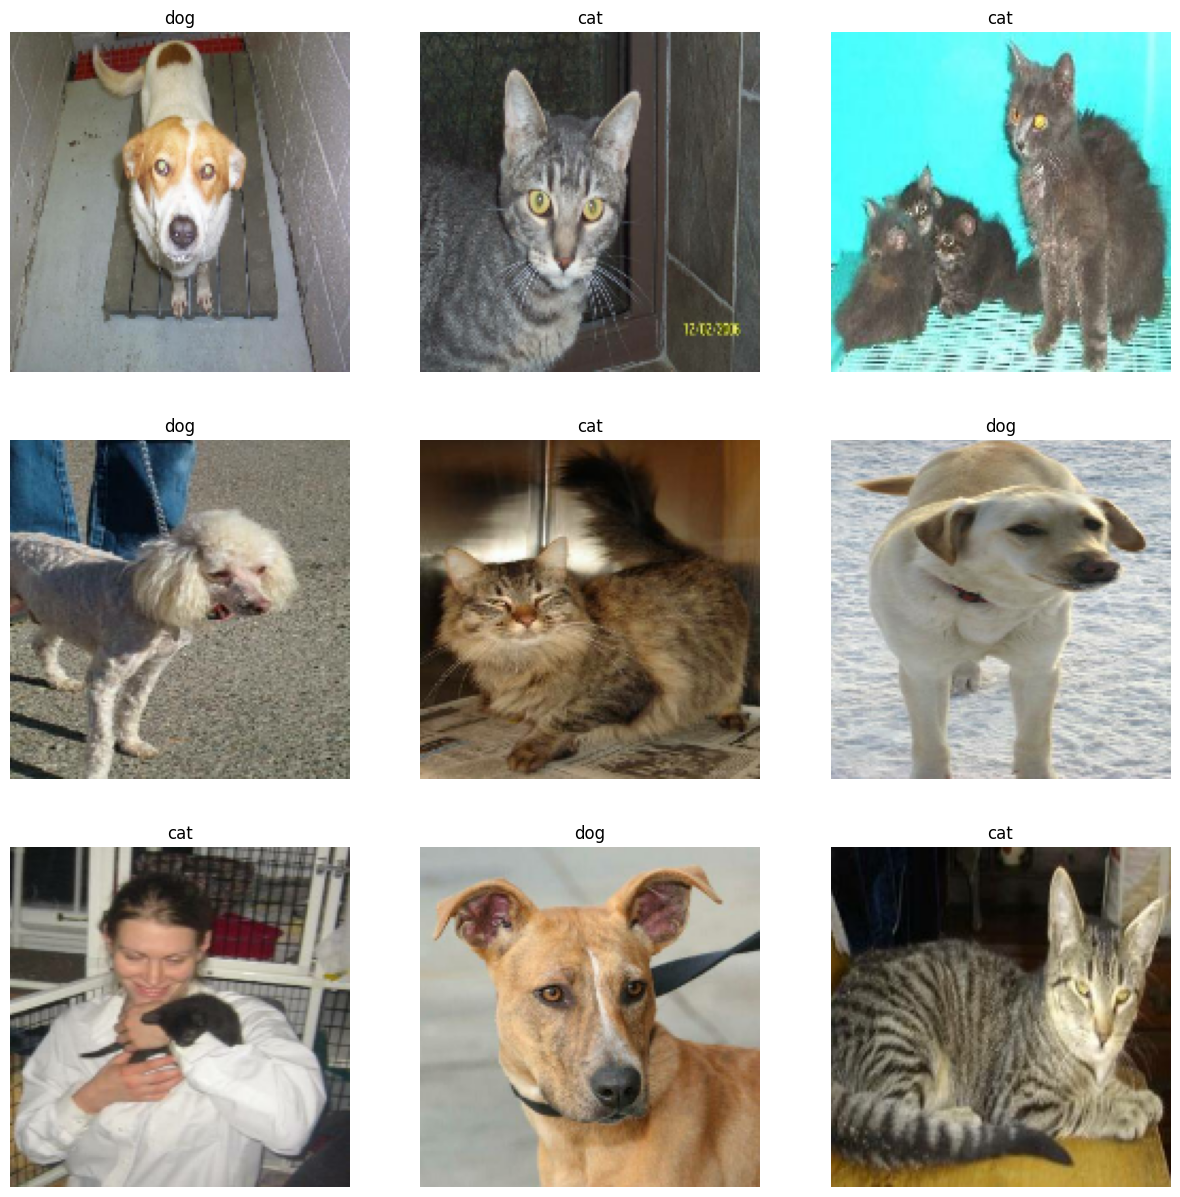

In [12]:
plot_dataset(dataset_train)

<Figure size 640x480 with 0 Axes>

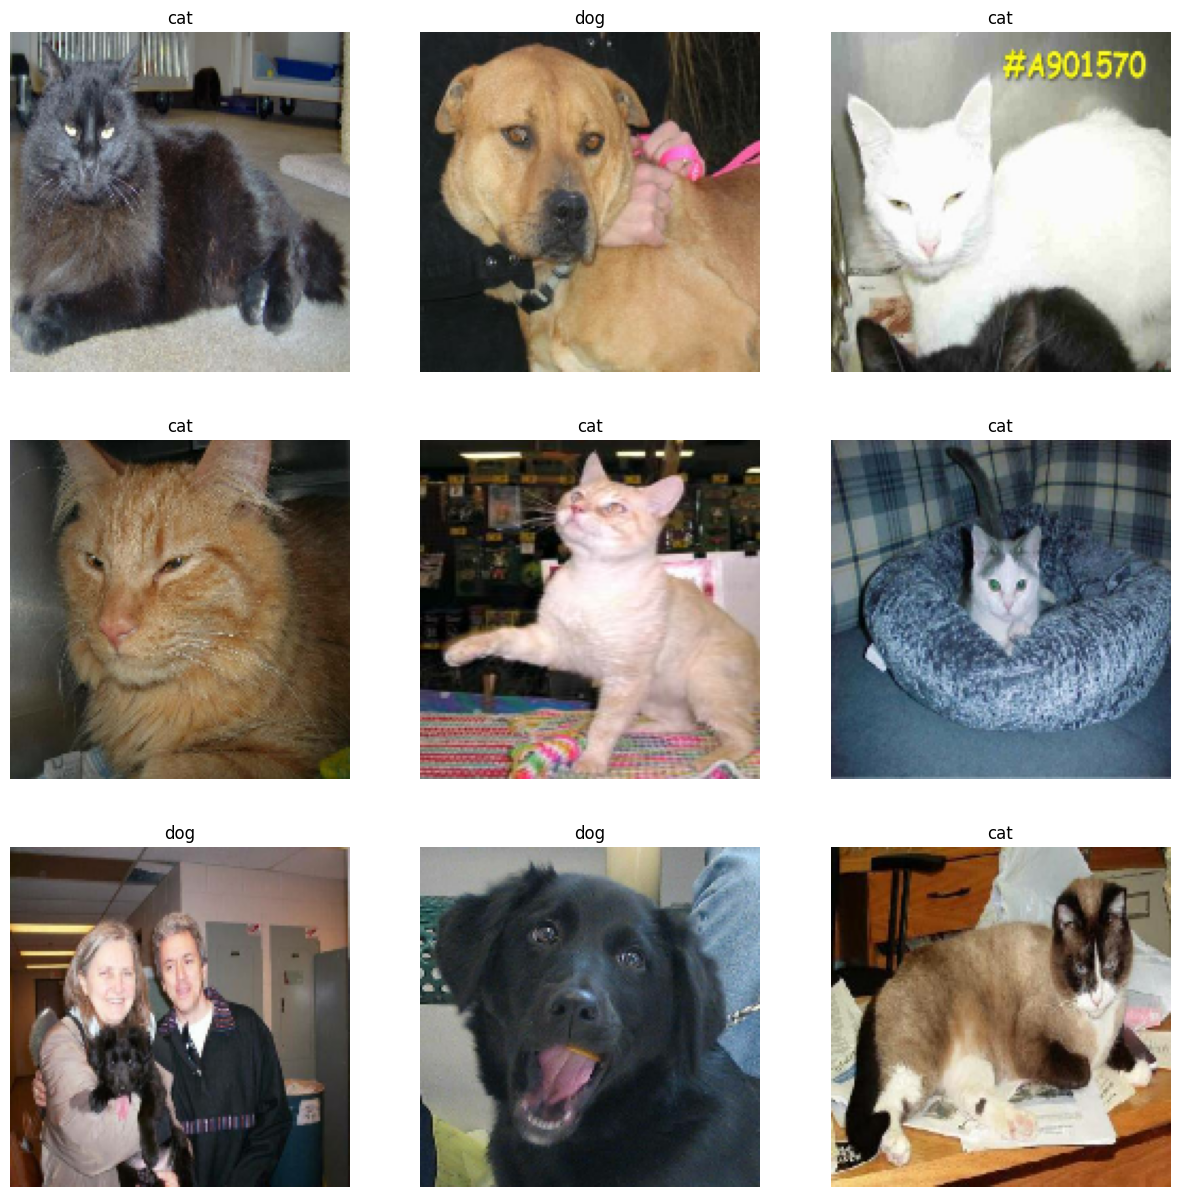

In [13]:
plot_dataset(dataset_validation)

<Figure size 640x480 with 0 Axes>

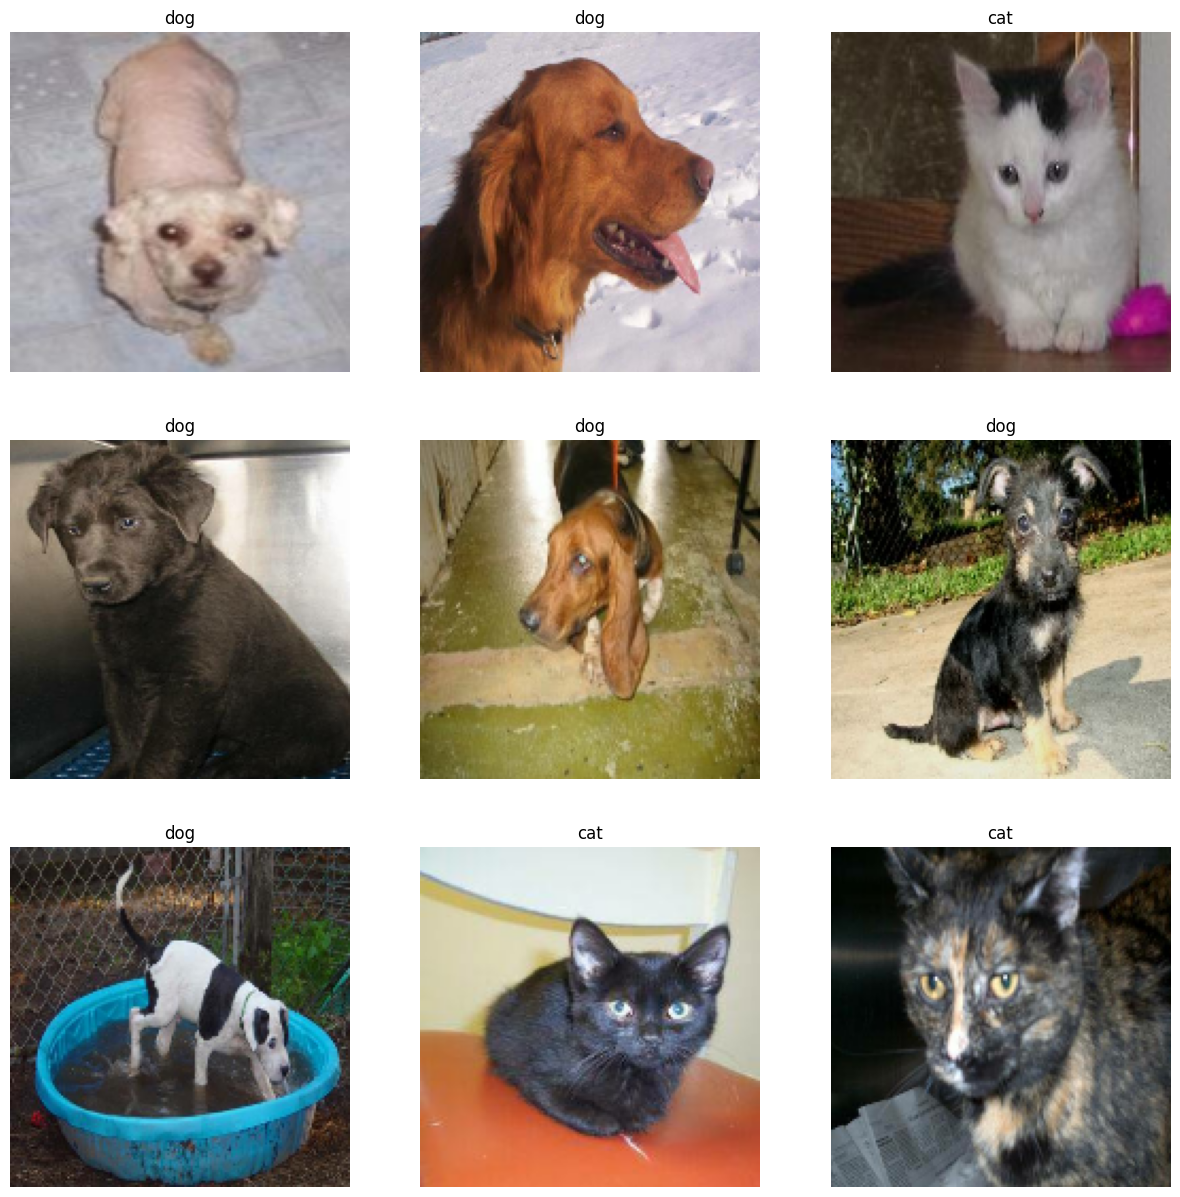

In [14]:
plot_dataset(dataset_test)

In [ ]:
#desenvolvimento do modelo
#parâmetros de treinamento

data_argumentation = tf.keras.models.Sequential([
    tf.keras.layers.experimental.preprocessing.RandomFlip('horizontal'),
    tf.keras.layers.experimental.preprocessing.RandomRotation(0.2),
    tf.keras.layers.experimental.preprocessing.RandomZoom(0.2)
])

In [ ]:
def plot_data_argumentation(dataset):
    plt.gcf().clear()
    plt.figure(figsize=(15, 15))

    for features, _ in dataset.take(1):
        feature = features[0]

        for i in range(9):
            feature_data_argumentation = data_argumentation(
                tf.expand_dims(feature, 0)
            )

            plt.subplot(3, 3, i + 1)
            plt.axis('off')
            plt.imshow(feature_data_argumentation[0] / image_color_channel_size)

  plot_dataset_data_argumentation(dataset_train)

In [ ]:
# transferência de aprendizagem

model_transfer_learning = tf.keras.applications.MobileNetV2(
    input_shape=image_shape,
    include_top=False,
    weights='imagenet'
)

model_transfer_learning.trainable = False

model_transfer_learning.summary()

In [15]:
#desenvolvimento do modelo
#parâmetros de treinamento

model = tf.keras.models.Sequential([
    tf.keras.layers.Rescaling(
        1./(image_color_channel_size / 2),
        offset = -1,
        input_shape=image_shape),

    #camadas convolucionais
    data_argumentation,
    model_transfer_learning,

    #camada de classificação
    tf.keras.layers.GlobalAveragePooling2D(),
    tf.keras.layers.Dropout(0.2),
    tf.keras.layers.Dense(1, activation='sigmoid')
])

#métricas de avaliação do modelo

model.compile(
    optimizer = tf.keras.optimizers.Adam(learning_rate=learning_rate),
    loss = tf.keras.losses.BinaryCrossentropy(),
    metrics = ['accuracy']
)

model.summary()

/usr/local/lib/python3.13/dist-packages/keras/src/layers/preprocessing/data_layer.py:95: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ rescaling (Rescaling)           │ (None, 160, 160, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 160, 160, 16)   │           448 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 80, 80, 16)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 80, 80, 32)     │         4,640 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 40, 40, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 40, 40, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 20, 20, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 25600)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │     3,276,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │           129 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 3,300,641 (12.59 MB)

 Trainable params: 3,300,641 (12.59 MB)

 Non-trainable params: 0 (0.00 B)

In [19]:
#avaliar métrica do modelo
history = model.fit(
  dataset_train,
  validation_data = dataset_validation,
  epochs = epochs
)

def plot_model():
  accuracy = history.history['accuracy']
  val_accuracy = history.history['val_accuracy']

  loss = history.history['loss']
  val_loss = history.history['val_loss']

  epochs_range = range(epochs)

  plt.gcf().clear()
  plt.figure(figsize=(15, 8))
  plt.subplot(1, 2, 1)
  plt.title('Training and Validation Accuracy')
  plt.plot(epochs_range, accuracy, label='Training Accuracy')
  plt.plot(epochs_range, val_accuracy, label='Validation Accuracy')
  plt.legend(loc='lower right')

  plt.subplot(1, 2, 2)
  plt.title('Training and Validation Loss')
  plt.plot(epochs_range, loss, label='Training Loss')
  plt.plot(epochs_range, val_loss, label='Validation Loss')
  plt.legend(loc='lower right')
  plt.show()

Epoch 1/20
63/63 ━━━━━━━━━━━━━━━━━━━━ 73s 1s/step - accuracy: 0.5435 - loss: 0.6916 - val_accuracy: 0.6337 - val_loss: 0.6632
Epoch 2/20
63/63 ━━━━━━━━━━━━━━━━━━━━ 64s 1s/step - accuracy: 0.6245 - loss: 0.6501 - val_accuracy: 0.6139 - val_loss: 0.6369
Epoch 3/20
63/63 ━━━━━━━━━━━━━━━━━━━━ 85s 1s/step - accuracy: 0.6500 - loss: 0.6232 - val_accuracy: 0.6869 - val_loss: 0.6080
Epoch 4/20
63/63 ━━━━━━━━━━━━━━━━━━━━ 70s 1s/step - accuracy: 0.6980 - loss: 0.5809 - val_accuracy: 0.7092 - val_loss: 0.5887
Epoch 5/20
63/63 ━━━━━━━━━━━━━━━━━━━━ 70s 1s/step - accuracy: 0.7285 - loss: 0.5465 - val_accuracy: 0.7141 - val_loss: 0.5827
Epoch 6/20
63/63 ━━━━━━━━━━━━━━━━━━━━ 89s 1s/step - accuracy: 0.7510 - loss: 0.5072 - val_accuracy: 0.7191 - val_loss: 0.5564
Epoch 7/20
63/63 ━━━━━━━━━━━━━━━━━━━━ 73s 1s/step - accuracy: 0.7735 - loss: 0.4786 - val_accuracy: 0.7351 - val_loss: 0.5392
Epoch 8/20
63/63 ━━━━━━━━━━━━━━━━━━━━ 87s 1s/step - accuracy: 0.7850 - loss: 0.4669 - val_accuracy: 0.7005 - val_loss:

In [ ]:
plot_model()

Labels: [1 0 1 1 1 1 1 1 0 1 1 0 1 0 0 0 0 1 0 1 0 1 0 0 1 0 0 0 1 1 0 1]
Predictions: [1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1]


<Figure size 640x480 with 0 Axes>

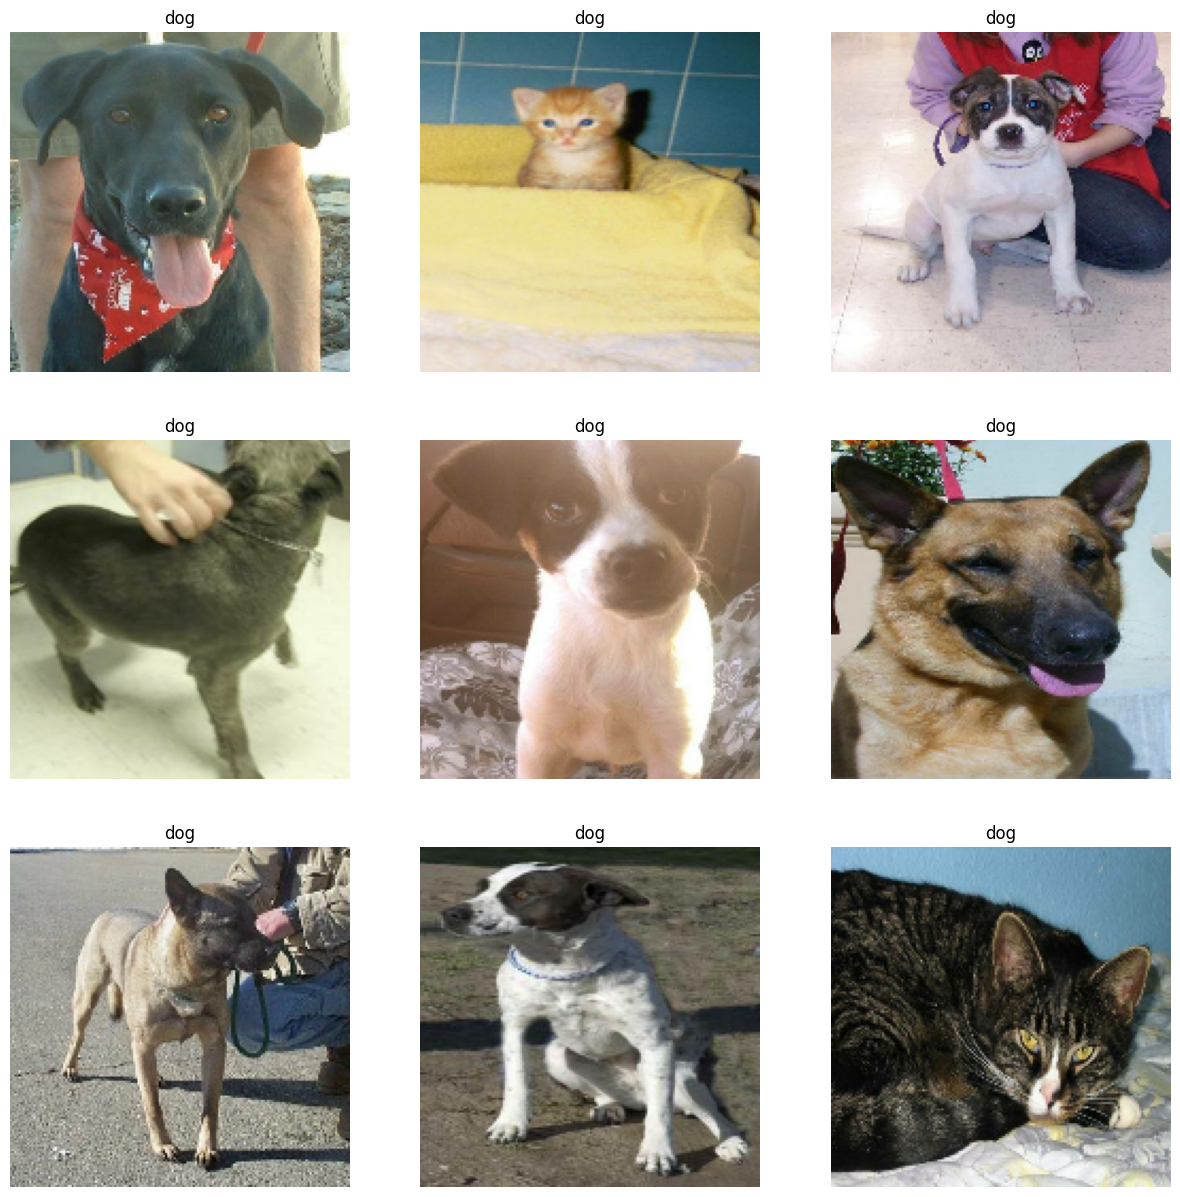

In [16]:
# testando o modelo diante de um novo dataset

def plot_dataset_predictions(dataset):
  features, labels = dataset.as_numpy_iterator().next()

  predictions = model.predict_on_batch(features).flatten()
  predictions = tf.where(predictions < 0.5, 0, 1)

  print('Labels: %s' % labels)
  print('Predictions: %s' % predictions.numpy())

  plt.gcf().clear()
  plt.figure(figsize=(15, 15))

  for i in range(9):
    plt.subplot(3, 3, i + 1)
    plt.axis('off')

    plt.imshow(features[i].astype('uint8'))
    plt.title(class_names[predictions[i]])

plot_dataset_predictions(dataset_test)

In [17]:
# salvar o modelo para a produção

model.save('modelo_gatos_caes.keras')

In [18]:
model = tf.keras.models.load_model('modelo_gatos_caes.keras')

/usr/local/lib/python3.13/dist-packages/keras/src/saving/saving_lib.py:797: UserWarning: Skipping variable loading for optimizer 'adam', because it has 22 variables whereas the saved optimizer has 2 variables. 
  saveable.load_own_variables(weights_store.get(inner_path))
